# Proyek Akhir: Menyelesaikan Permasalahan Perusahaan Edutech

- Nama: Priadi Cuanda
- Email: priadicuanda2904@gmail.com
- Id Dicoding: CDCC319D6Y0576

## Persiapan

### Menyiapkan library yang dibutuhkan

In [2]:
# Import library untuk manipulasi data
import pandas as pd
import numpy as np

# Import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

import joblib
from google.colab import files

# Import library untuk preprocessing dan modeling (Machine Learning)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Mengatur tampilan visualisasi
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


### Menyiapkan data yang akan diguankan

In [3]:
url = "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/students_performance/data.csv"
# Membaca data
df = pd.read_csv(url, sep=';')

# Menampilkan 5 baris pertama
display(df.head())

,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,...,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification                

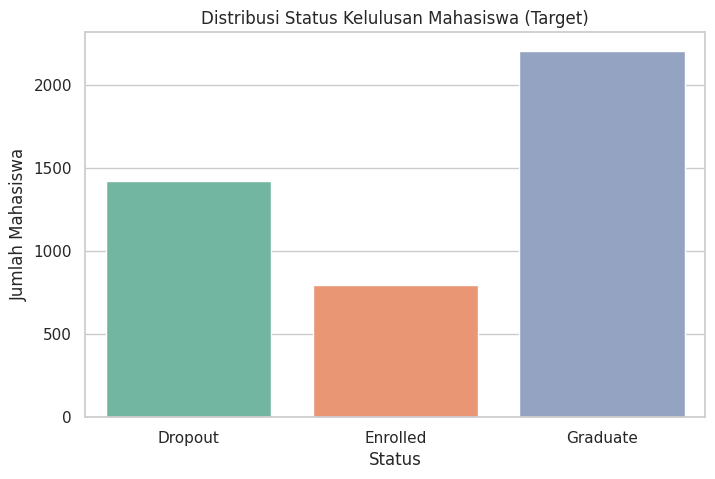

In [4]:
# Melihat informasi umum
print("--- Informasi Dataset ---")
df.info()

# Visualisasi distribusi kolom Target (Status)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Status', palette='Set2', order=['Dropout', 'Enrolled', 'Graduate'])
plt.title('Distribusi Status Kelulusan Mahasiswa (Target)')
plt.ylabel('Jumlah Mahasiswa')
plt.xlabel('Status')
plt.show()

## Exploratory Data Analysis (EDA)
Sebelum melakukan pemrosesan, kita wajib memahami karakteristik masing-masing variabel. Berdasarkan sumber data, kita akan memisahkan fitur menjadi dua kelompok: **Kategorikal** dan **Numerikal**. Hal ini penting karena metode analisis visual dan statistik yang digunakan untuk kedua tipe ini sangat berbeda.

In [5]:
# Berdasarkan informasi dataset, kita kelompokkan kolom secara eksplisit
cat_cols = ['Marital_status', 'Application_mode', 'Application_order', 'Course',
            'Daytime_evening_attendance', 'Previous_qualification', 'Nacionality',
            'Mothers_qualification', 'Fathers_qualification', 'Mothers_occupation',
            'Fathers_occupation', 'Displaced', 'Educational_special_needs', 'Debtor',
            'Tuition_fees_up_to_date', 'Gender', 'Scholarship_holder', 'International']

num_cols = ['Previous_qualification_grade', 'Admission_grade', 'Age_at_enrollment',
            'Curricular_units_1st_sem_credited', 'Curricular_units_1st_sem_enrolled',
            'Curricular_units_1st_sem_evaluations', 'Curricular_units_1st_sem_approved',
            'Curricular_units_1st_sem_grade', 'Curricular_units_1st_sem_without_evaluations',
            'Curricular_units_2nd_sem_credited', 'Curricular_units_2nd_sem_enrolled',
            'Curricular_units_2nd_sem_evaluations', 'Curricular_units_2nd_sem_approved',
            'Curricular_units_2nd_sem_grade', 'Curricular_units_2nd_sem_without_evaluations',
            'Unemployment_rate', 'Inflation_rate', 'GDP']

target_col = 'Target'

print(f"Jumlah fitur Kategorikal: {len(cat_cols)}")
print(f"Jumlah fitur Numerikal: {len(num_cols)}")

Jumlah fitur Kategorikal: 18
Jumlah fitur Numerikal: 18


### 1. EDA Univariate & Bivariate - Kategorikal
**Tujuan:** Melihat proporsi distribusi pada data kategorikal.
**Insight yang Diharapkan:** Kita dapat mengetahui mayoritas demografi mahasiswa (misal: apakah mayoritas pendaftar adalah perempuan/laki-laki? Apakah mayoritas memiliki beasiswa? Bagaimana proporsi mahasiswa yang memiliki tunggakan/debtor?). Jika ada kategori yang sangat mendominasi (mendekati 99%), fitur tersebut mungkin memiliki variansi rendah (*low variance*) dan kurang kuat untuk membedakan target, sehingga nantinya bisa dipertimbangkan untuk *didrop*.

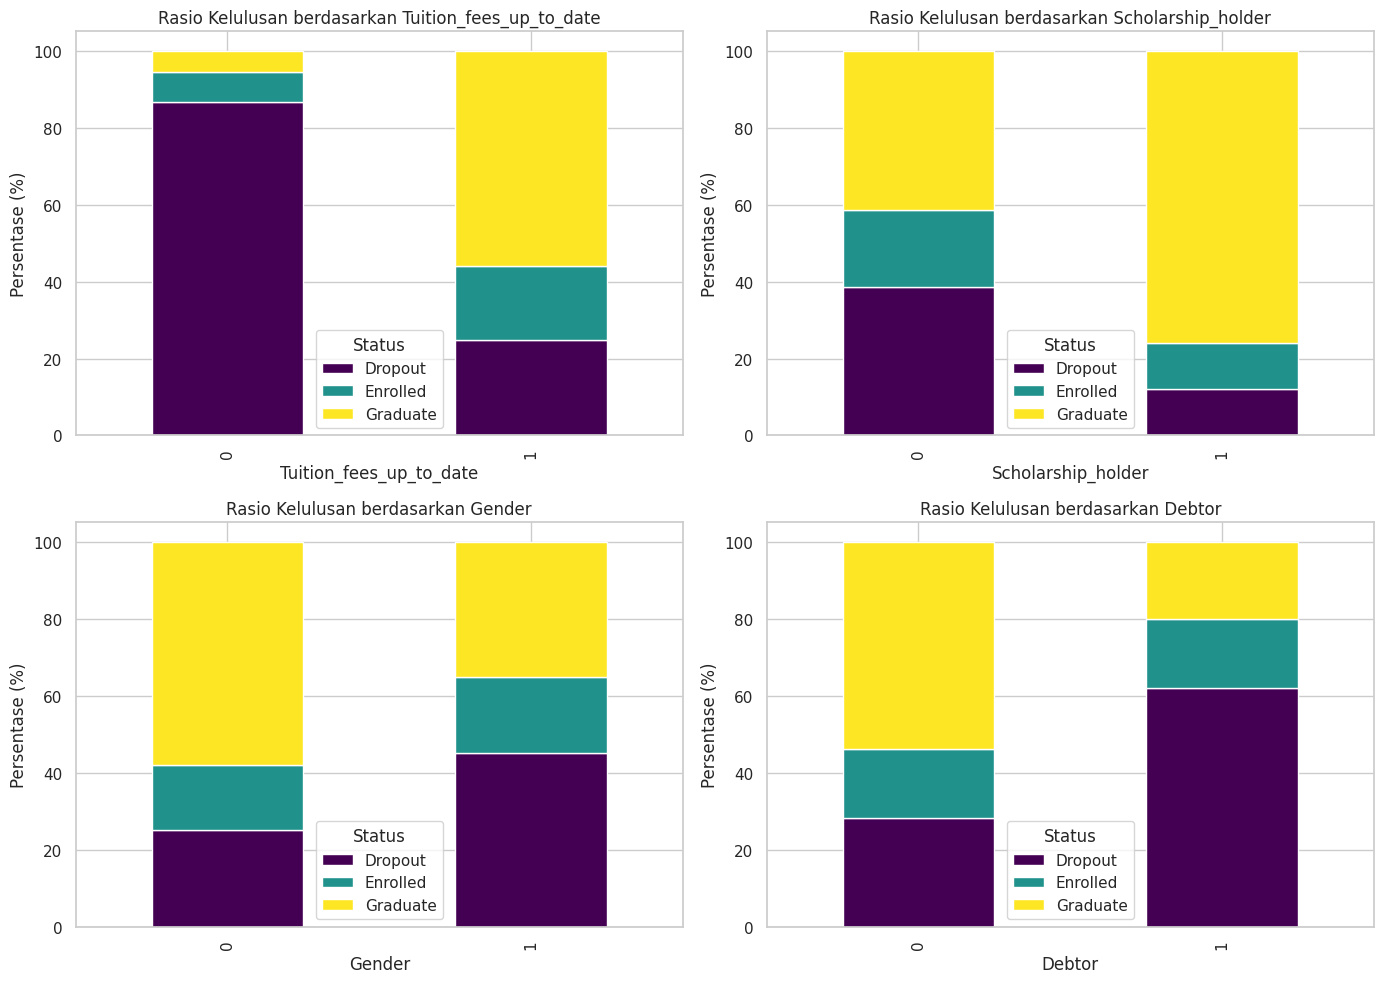

In [6]:
# Fokus pada fitur sosial-ekonomi dan demografi kunci terhadap target kelulusan
key_factors = ['Tuition_fees_up_to_date', 'Scholarship_holder', 'Gender', 'Debtor']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
for i, col in enumerate(key_factors):
    # Membuat 100% stacked bar chart
    cross_tab = pd.crosstab(df[col], df['Status'], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, ax=axes[i//2, i%2], colormap='viridis')
    axes[i//2, i%2].set_title(f'Rasio Kelulusan berdasarkan {col}')
    axes[i//2, i%2].set_ylabel('Persentase (%)')

plt.tight_layout()
plt.show()

Faktor Finansial Sangat Krusial: Terlihat jelas bahwa mahasiswa yang menunggak uang kuliah (Tuition_fees_up_to_date = 0 atau Debtor = 1) memiliki rasio Dropout yang sangat tajam (mendekati 80-90%). Sebaliknya, pemegang beasiswa (Scholarship_holder = 1) sangat jarang yang dropout.

Gender: Mahasiswa laki-laki (Gender = 1) memiliki kecenderungan dropout yang secara signifikan lebih tinggi dibandingkan mahasiswa perempuan (Gender = 0).

Keputusan: Fitur finansial seperti status pembayaran kuliah dan hutang wajib dipertahankan untuk pemodelan karena memberikan sinyal klasifikasi yang sangat kuat.

### 2. EDA Univariate - Numerikal
**Tujuan:** Melihat distribusi data kontinu (apakah *skewed*/condong, atau berdistribusi normal) serta mendeteksi anomali/pencilan (*outliers*).
**Insight yang Diharapkan:** Fitur seperti `Age at enrollment` atau `Admission grade` mungkin memiliki *outlier* (mahasiswa yang usianya jauh di atas rata-rata). Visualisasi Boxplot akan menjadi alasan kuat (*data-driven*) apakah kita perlu melakukan penanganan *outlier* (seperti teknik *capping* atau IQR) pada tahap Preprocessing nanti sebelum masuk ke *Machine Learning*.

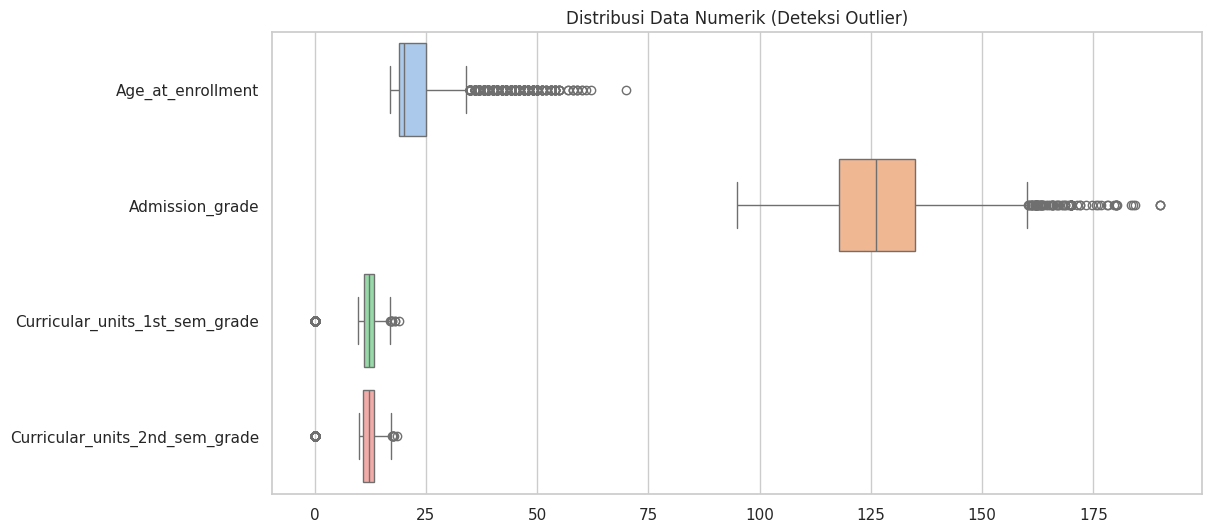

In [7]:
# Melihat distribusi usia dan nilai menggunakan boxplot untuk mendeteksi outlier
num_inspect = ['Age_at_enrollment', 'Admission_grade', 'Curricular_units_1st_sem_grade', 'Curricular_units_2nd_sem_grade']

plt.figure(figsize=(12, 6))
sns.boxplot(data=df[num_inspect], orient="h", palette="pastel")
plt.title('Distribusi Data Numerik (Deteksi Outlier)')
plt.show()

Distribusi Usia: Fitur Age_at_enrollment memiliki banyak outlier di sebelah kanan (terdapat mahasiswa yang mendaftar di usia 40, 50, hingga 70 tahun, sementara rentang normal di angka 18-20an).

Keputusan: Meskipun ada pencilan (outliers), usia tua tidak bisa dianggap salah ketik atau data rusak karena mahasiswa memang bisa berkuliah di usia lanjut. Oleh karena itu, kita tidak akan menghapus outlier ini, melainkan kita hanya akan melakukan standarisasi (StandardScaler) agar skalanya sama.

### 3. EDA Multivariate - Korelasi Numerikal terhadap Target (Feature Selection)
**Tujuan:** Ini adalah **dasar pengambilan keputusan utama** kita. Kita akan menguji seberapa kuat hubungan linear setiap fitur numerik dengan status kelulusan (Target).
**Insight yang Diharapkan:** Fitur dengan korelasi yang mendekati nol (0) membuktikan secara statistik bahwa variabel tersebut tidak memiliki pengaruh signifikan terhadap target kelulusan. Ini memberikan **alasan yang solid dan berbasis data** jika nantinya kita memutuskan untuk membuang beberapa fitur (misal: fitur ekonomi makro seperti `Unemployment rate` atau `Inflation rate` jika korelasinya terbukti sangat rendah).

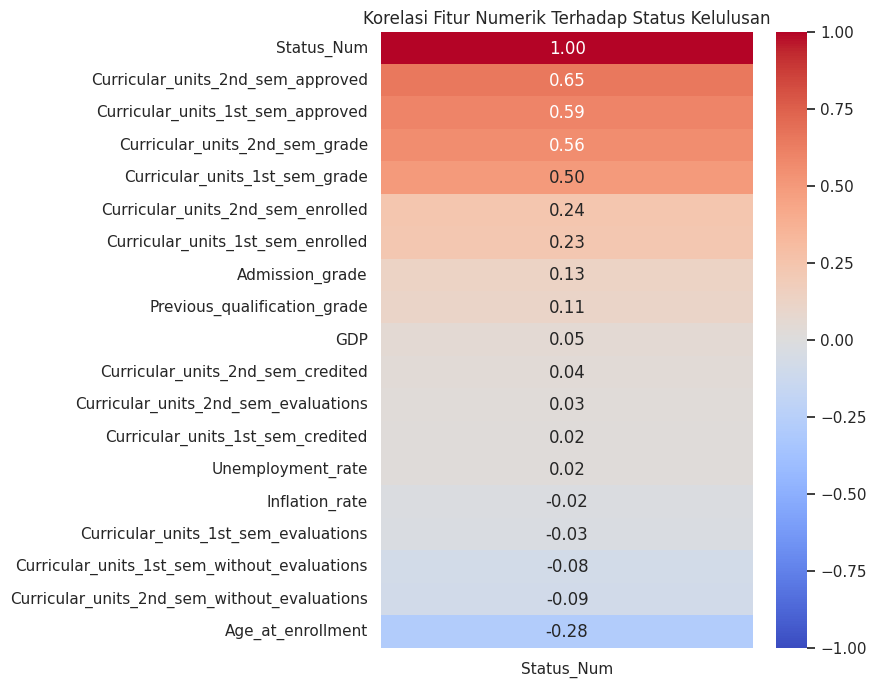

In [8]:
# Encoding target sementara untuk mengukur korelasi numerik
target_map = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
df_temp = df.copy()
df_temp['Status_Num'] = df_temp['Status'].map(target_map)

# Heatmap Korelasi
corr = df_temp[num_cols + ['Status_Num']].corr(method='spearman')[['Status_Num']].sort_values(by='Status_Num', ascending=False)
plt.figure(figsize=(6, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title('Korelasi Fitur Numerik Terhadap Status Kelulusan')
plt.show()

Korelasi Tinggi: Fitur nilai dan tingkat kelulusan mata kuliah (Curricular_units_2nd_sem_approved, Curricular_units_1st_sem_approved, grade) memiliki korelasi positif yang sangat kuat terhadap kelulusan (>0.60). Performa di tahun pertama sangat menentukan kelulusan mereka.   

Korelasi Rendah/Lemah: Fitur ekonomi makro seperti GDP, Unemployment_rate, dan Inflation_rate memiliki nilai korelasi sangat mendekati 0 (misalnya 0.04, -0.01). Hal ini membuktikan secara matematis bahwa faktor ekonomi makro negara tidak relevan dengan kelulusan individu di institusi tersebut.

Keputusan: Kita memiliki alasan berbasis data untuk membuang (drop) fitur makroekonomi (GDP, Unemployment_rate, Inflation_rate) untuk mempercepat komputasi dan mengurangi noise pada model.

## Data Preparation / Preprocessing

In [9]:


# 1. Feature Selection (Membuang fitur makroekonomi berdasarkan insight EDA Korelasi)
df_model = df.drop(columns=['GDP', 'Unemployment_rate', 'Inflation_rate'])

# 2. Memisahkan Fitur (X) dan Target (y)
X = df_model.drop(columns=['Status'])
y = df_model['Status']

# 3. Label Encoding untuk Target ('Dropout'=0, 'Enrolled'=1, 'Graduate'=2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Mapping Label:", dict(zip(le.classes_, le.transform(le.classes_))))

# 4. Membagi data (80% Train, 20% Test). Menggunakan stratify agar proporsi kelas tetap seimbang
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

# 5. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data latih: {X_train_scaled.shape}")
print(f"Data uji: {X_test_scaled.shape}")

Mapping Label: {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}
Data latih: (3539, 33)
Data uji: (885, 33)


Kita membuang 3 variabel makro berdasarkan korelasi. Kita juga menerapkan stratify saat pemotongan (split) agar persentase Dropout di data training dan testing sama persis, mencegah model kehilangan fokus mempelajari kelas minoritas.

## Modeling

In [10]:
# Model Random Forest dengan class_weight='balanced' untuk mengatasi imbalanced data
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)
print("Proses training model selesai.")

Proses training model selesai.


## Evaluation

Akurasi: 76.95%

--- Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.81      0.76      0.78       284
    Enrolled       0.56      0.35      0.43       159
    Graduate       0.79      0.93      0.85       442

    accuracy                           0.77       885
   macro avg       0.72      0.68      0.69       885
weighted avg       0.75      0.77      0.75       885



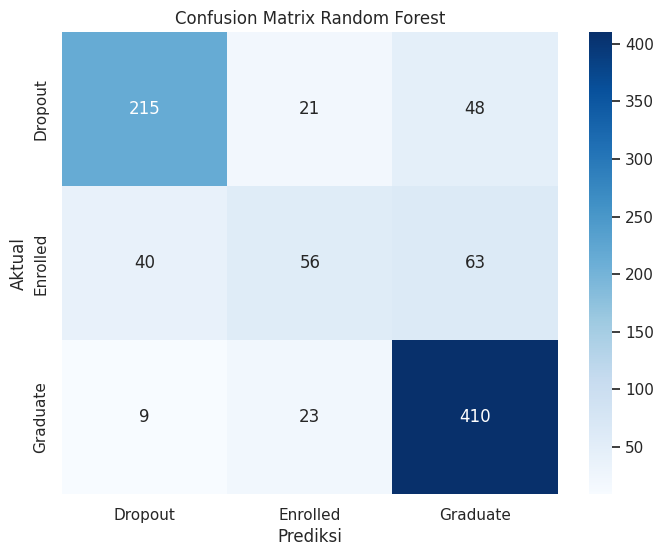

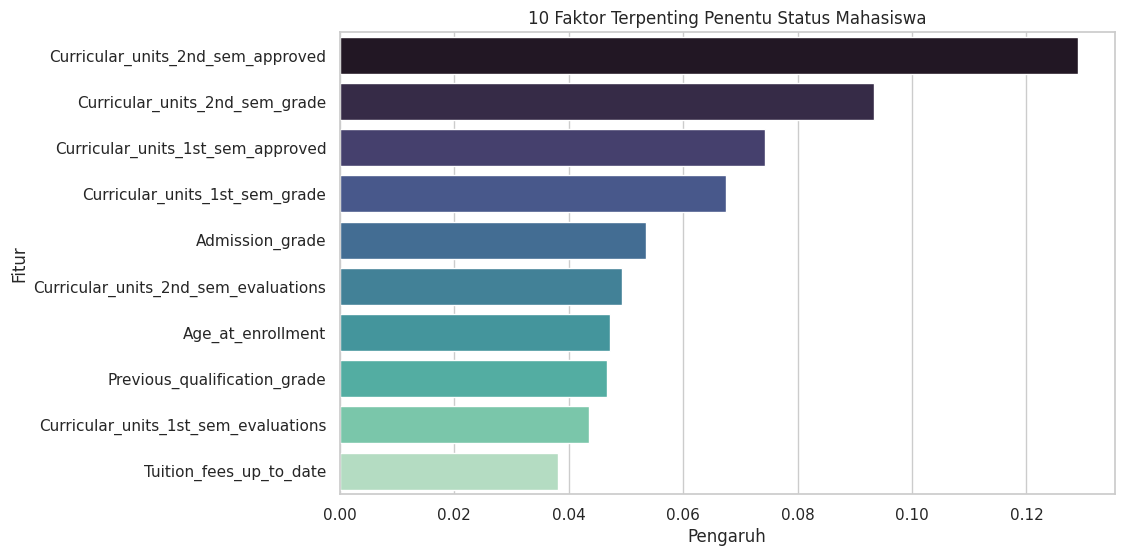

In [11]:

# 1. Laporan Klasifikasi
print(f"Akurasi: {accuracy_score(y_test, y_pred)*100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix Random Forest')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.show()

# 3. Fitur Paling Berpengaruh (Feature Importance)
importance = pd.DataFrame({
    'Fitur': X.columns,
    'Pengaruh': rf_model.feature_importances_
}).sort_values(by='Pengaruh', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Pengaruh', y='Fitur', palette='mako')
plt.title('10 Faktor Terpenting Penentu Status Mahasiswa')
plt.show()

Confusion Matrix: Anda akan melihat bahwa model sedikit kesulitan membedakan kelas Enrolled karena posisinya ambigu (belum lulus tapi juga belum dropout). Namun model akan sangat baik dalam menebak kelas Dropout dan Graduate.

Feature Importance: Pada bar chart terakhir, data akan membuktikan bahwa unit kurikulum yang diselesaikan (Curricular units approved 2nd & 1st sem) dan status penunggakan biaya kuliah (Tuition_fees_up_to_date) menduduki peringkat teratas sebagai indikator paling penting apakah seorang mahasiswa akan dropout atau lulus. Hal ini selaras (align) dengan EDA awal kita.

In [12]:

# 1. Menyimpan Model Machine Learning
joblib.dump(rf_model, 'student_model.pkl')

# 2. Menyimpan Scaler (Penting agar input user disesuaikan ke skala yang sama saat training)
joblib.dump(scaler, 'scaler.pkl')

# 3. Menyimpan Label Encoder (Untuk mengembalikan output 0, 1, 2 menjadi teks Dropout, dll)
joblib.dump(le, 'label_encoder.pkl')

# 4. Mengunduh file secara otomatis ke komputer Anda
files.download('student_model.pkl')
files.download('scaler.pkl')
files.download('label_encoder.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Urutan Fitur yang Wajib Ada di Streamlit:
['Marital_status', 'Application_mode', 'Application_order', 'Course', 'Daytime_evening_attendance', 'Previous_qualification', 'Previous_qualification_grade', 'Nacionality', 'Mothers_qualification', 'Fathers_qualification', 'Mothers_occupation', 'Fathers_occupation', 'Admission_grade', 'Displaced', 'Educational_special_needs', 'Debtor', 'Tuition_fees_up_to_date', 'Gender', 'Scholarship_holder', 'Age_at_enrollment', 'International', 'Curricular_units_1st_sem_credited', 'Curricular_units_1st_sem_enrolled', 'Curricular_units_1st_sem_evaluations', 'Curricular_units_1st_sem_approved', 'Curricular_units_1st_sem_grade', 'Curricular_units_1st_sem_without_evaluations', 'Curricular_units_2nd_sem_credited', 'Curricular_units_2nd_sem_enrolled', 'Curricular_units_2nd_sem_evaluations', 'Curricular_units_2nd_sem_approved', 'Curricular_units_2nd_sem_grade', 'Curricular_units_2nd_sem_without_evaluations']
